# La escalera de estimadores: de la simulación histórica a GARCH, EVT, CAViaR y GAS-FZ

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (VaR, ES y un primer conteo de excepciones)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar los escalones de la escalera de estimadores de VaR y ES que corre Contraste, desde la simulación histórica hasta los modelos semiparamétricos dinámicos, y decir qué supone cada uno;
- verificar en un artefacto versionado que cada pronóstico se hizo con información fechada antes de su día y que los hiperparámetros se fijaron antes de las ventanas en que se puntúan;
- correr los escalones de forma cerrada (simulación ponderada por edad, EWMA, delta-normal, Cornish-Fisher, simulación histórica filtrada y la cola por excedencias sobre un umbral) sobre retornos reales con las funciones del motor, y verificar el pronóstico EWMA versionado contra su propia recursión;
- decir qué escalones no se pueden reajustar en un cuaderno y por qué, y leer sus parámetros ajustados y sus fallas de convergencia de la escalera versionada;
- leer, para seis ventanas de mercado, cuántas veces cada escalón superó su VaR al 1 por ciento, y qué escalones sacaron las compuertas de elegibilidad.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 tal como Contraste lo versiona: un documento por ventana de mercado más el documento de la escalera misma.

- `data/derived/C11/models-ladder.json`: las 18 entradas de la escalera (17 escalones ajustados y un retador que no se ejecutó), cada una con su fuente, innovación, ventana de estimación, frecuencia de reajuste y, por ventana, el número de reajustes, las fallas de convergencia y el rango de sus parámetros ajustados.
- `data/derived/C11/<ventana>.json` para las seis ventanas: `calm-2004-06`, `equity-2007-09`, `equity-2020`, `rates-2022`, `fx-2008` y `mixed-2023`. Cada uno guarda, para cada modelo y nivel de cola, la trayectoria de VaR y ES, los días de excepción y el veredicto de elegibilidad.

Las clases de licencia deciden qué se versiona. De las seis ventanas solo `rates-2022` y `fx-2008` versionan las pérdidas realizadas (datos del Tesoro y H.10 de la Reserva Federal, `mirror-allowed`); las ventanas accionarias y la mixta contienen el retorno de Kenneth French, `derived-only`, así que versionan pronósticos y días de excepción pero no retornos. Los estimadores no se pueden reajustar en una ventana cuyos retornos de estimación no se versionan, y de ninguna ventana se versionan los 1.000 días de estimación. El cuaderno lee entonces los pronósticos versionados de los escalones ajustados y corre los escalones de forma cerrada sobre los 251 retornos realizados de `fx-2008`, diciendo cada vez qué cambia eso. La celda siguiente carga los siete archivos.

In [2]:
# Cargar el documento de la escalera y los seis documentos de ventana (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
ladder_doc = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}

print("escalera calculada por riskvalidation", ladder_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for w, doc in windows.items():
    out = doc["outputs"]
    print(f"{w:15s} {out['window']['start_date']} a {out['window']['end_date']} | {out['window']['n_forecast_days']:4d} días | "
          f"pérdidas realizadas {si_no(out['grid']['realised_loss']['status'])}")

escalera calculada por riskvalidation 0.7.0 | instalado 0.9.0
calm-2004-06    2004-01-02 a 2006-12-29 |  750 días | pérdidas realizadas retenidas, solo derivados
equity-2007-09  2007-07-02 a 2009-06-30 |  504 días | pérdidas realizadas retenidas, solo derivados
equity-2020     2020-02-03 a 2020-06-30 |  104 días | pérdidas realizadas retenidas, solo derivados
rates-2022      2022-01-03 a 2022-12-30 |  249 días | pérdidas realizadas incluidas
fx-2008         2008-07-01 a 2009-06-30 |  251 días | pérdidas realizadas incluidas
mixed-2023      2023-03-01 a 2023-05-31 |   64 días | pérdidas realizadas retenidas, solo derivados


## Método

### Paso 1: la escalera

Un escalón es una manera de convertir retornos pasados en el VaR y la ES de mañana. La escalera va desde la línea base transparente hasta la frontera académica actual, de modo que un validador pueda preguntar de cualquier escalón complejo si supera al simple que reemplaza. El documento de la escalera lista cada escalón con su fuente, la distribución que supone para las innovaciones (`innovation`), cuántos días pasados lee y cada cuánto se reajusta. La celda siguiente lo imprime. La última entrada, `nn-fz`, es un retador neuronal de la literatura que el cálculo **no** entrena; el documento lo dice en lugar de omitirlo.

In [3]:
# Imprimir la escalera: escalón, estimador, innovación, días leídos, período de reajuste y si pronostica una ES
YES_NO = {True: "sí", False: "no"}
INNOVACION = {"empirical": "empírica", "normal": "normal", "student-t": "t de Student", "gpd-tail": "cola GPD", "none": "ninguna"}
fuente = lambda s: s.replace(" and ", " y ").replace("challenger only", "solo retador").replace("two-step estimation declared in the engine", "estimación en dos pasos declarada en el motor")
print(f"{'modelo':11s} {'esc.':5s} {'innovación':12s} {'días':>5s} {'reaj.':>5s} {'ES':>3s}  estado")
for entry in ladder_doc["fit"]["ladder"]:
    days = entry["estimation_window_days"] if entry["estimation_window_days"] is not None else "-"
    refit = entry["refit_every_days"] if entry["refit_every_days"] is not None else "-"
    print(f"{entry['model_id']:11s} {entry['rung']:5s} {INNOVACION[entry['innovation']]:12s} {days!s:>5s} {refit!s:>5s} {YES_NO[entry['forecasts_es']]:>3s}  {si_no(entry['status'])}")
challenger = ladder_doc["fit"]["ladder"][-1]
print("no ejecutado:", challenger["model_id"], "|", fuente(challenger["source"]))

modelo      esc.  innovación    días reaj.  ES  estado
hs-250      R1    empírica       250     1  sí  ajustado
hs-500      R1    empírica       500     1  sí  ajustado
awhs        R2    empírica       250     1  sí  ajustado
dn-rolling  R3    normal        1000     1  sí  ajustado
cf-rolling  R3    normal        1000     1  no  ajustado
ewma        R4    normal        1000     1  sí  ajustado
garch-t     R5    t de Student  1000     1  sí  ajustado
gjr-t       R5    t de Student  1000     1  sí  ajustado
egarch-t    R5    t de Student  1000     1  sí  ajustado
fhs         R6    empírica      1000     1  sí  ajustado
evt-mf      R7    cola GPD      1000     1  sí  ajustado
caviar-sav  R8    ninguna       1000     5  no  ajustado
caviar-as   R8    ninguna       1000     5  no  ajustado
caviar-es   R8    ninguna       1000     5  sí  ajustado
gas-fz-1    R9    ninguna       1000    20  sí  ajustado
gas-fz-2    R9    ninguna       1000    20  sí  ajustado
gas-hybrid  R9    ninguna       1

### Paso 2: sin mirar hacia adelante, hiperparámetros fijados de antemano

Dos reglas vuelven honesto un backtest. Primero, cada pronóstico usa solo retornos fechados **antes** de su día: cada documento de ventana registra, para cada fecha de pronóstico, el primer y el último día de la muestra de estimación (`grid.estimation_start`, `grid.estimation_end`). Segundo, los hiperparámetros (el decaimiento de EWMA, el de la ponderación por edad, la fracción del umbral EVT, el número de partidas del optimizador) se eligen sobre un tramo que termina antes de que empiece cada ventana, nunca sobre la ventana que se puntúa (`hyperparameters.fixed_on`, `tuned_on_test_window`). Ambas reglas se pueden verificar en el archivo versionado, lo que hace la celda siguiente con las seis ventanas.

In [4]:
# Verificar las dos reglas en cada ventana: la muestra de estimación termina antes de cada fecha, los hiperparámetros antes de la ventana
for w, doc in windows.items():
    out = doc["outputs"]
    grid, hyper = out["grid"], out["hyperparameters"]
    before = all(end < day for end, day in zip(grid["estimation_end"], grid["dates"]))
    fixed_before = hyper["fixed_on"]["end"] < out["window"]["start_date"]
    print(f"{w:15s} esquema {grid['scheme']} {grid['estimation_window_days']} días | cada muestra de estimación termina antes de su día: {si_no(before)} | "
          f"hiperparámetros fijados en {hyper['fixed_on']['start']} a {hyper['fixed_on']['end']}, antes de la ventana: {si_no(fixed_before)} | "
          f"ajustados sobre la ventana de prueba: {si_no(hyper['tuned_on_test_window'])}")

hyper = windows["fx-2008"]["outputs"]["hyperparameters"]
print({key: hyper[key] for key in ("ewma_lambda", "age_weight_lambda", "evt_threshold_fraction", "garch_refit_every_days", "caviar_n_starts", "gas_n_starts", "seed")})

calm-2004-06    esquema rolling 1000 días | cada muestra de estimación termina antes de su día: sí | hiperparámetros fijados en 1995-01-01 a 2003-12-31, antes de la ventana: sí | ajustados sobre la ventana de prueba: no
equity-2007-09  esquema rolling 1000 días | cada muestra de estimación termina antes de su día: sí | hiperparámetros fijados en 1995-01-01 a 2003-12-31, antes de la ventana: sí | ajustados sobre la ventana de prueba: no
equity-2020     esquema rolling 1000 días | cada muestra de estimación termina antes de su día: sí | hiperparámetros fijados en 1995-01-01 a 2003-12-31, antes de la ventana: sí | ajustados sobre la ventana de prueba: no
rates-2022      esquema rolling 1000 días | cada muestra de estimación termina antes de su día: sí | hiperparámetros fijados en 1995-01-01 a 2003-12-31, antes de la ventana: sí | ajustados sobre la ventana de prueba: no
fx-2008         esquema rolling 1000 días | cada muestra de estimación termina antes de su día: sí | hiperparámetros fij

### Paso 3: simulación histórica ponderada por edad (escalón R2)

La simulación histórica simple da el mismo peso a cada día de la ventana, de modo que un día de crisis sale de la ventana de una vez y el VaR salta. Boudoukh, Richardson y Whitelaw (1998) ponderan el retorno observado hace $i$ días por

$$w_i = \frac{1-\lambda}{1-\lambda^{K}}\,\lambda^{\,i-1}, \qquad i = 1,\dots,K$$

ordenan los retornos, acumulan los pesos hasta alcanzar $\alpha$ e interpolan. La función `age_weights(lam, k)` del motor devuelve los pesos y `age_weighted_var_es(returns, alpha, lam, window)` el pronóstico; la ES es la integral de cola de la misma función cuantil interpolada (el artículo no da regla para la ES, el motor documenta esto como su decisión D-9). Usamos el $\lambda$ versionado y los primeros 100 retornos de `fx-2008`, una ventana más corta que el $K = 250$ versionado, y comparamos con el pronóstico de pesos iguales al nivel de 2,5 por ciento, donde la cola contiene 2,5 observaciones.

In [5]:
# Pesos por edad con el decaimiento versionado, y el pronóstico ponderado por edad frente al de pesos iguales sobre los mismos 100 retornos
from riskvalidation.market.historical import age_weighted_var_es, age_weights, historical_var_es

fx_out = windows["fx-2008"]["outputs"]
y = -np.array(fx_out["grid"]["realised_loss"]["loss"])      # los 251 retornos realizados, convención del motor
lam_age = fx_out["hyperparameters"]["age_weight_lambda"]
K = 100
weights = age_weights(lam_age, K)
print(f"lambda {lam_age}, K {K}: los pesos suman {weights.sum():.6f} | día más reciente {weights[0]:.5f} | día más antiguo {weights[-1]:.5f}")
print(f"número efectivo de días 1 / sum(w^2): {1 / np.sum(weights ** 2):.1f} de {K}")

sample = y[:K]
for alpha in (0.01, 0.025):
    var_eq, es_eq = historical_var_es(sample, alpha, K)
    var_aw, es_aw = age_weighted_var_es(sample, alpha, lam_age, K)
    print(f"alfa {alpha}: pesos iguales VaR {-var_eq:.6f} ES {-es_eq:.6f} | pesos por edad VaR {-var_aw:.6f} ES {-es_aw:.6f}")

lambda 0.99, K 100: los pesos suman 1.000000 | día más reciente 0.01577 | día más antiguo 0.00583
número efectivo de días 1 / sum(w^2): 92.4 de 100
alfa 0.01: pesos iguales VaR 0.022293 ES 0.022293 | pesos por edad VaR 0.022072 ES 0.022246
alfa 0.025: pesos iguales VaR 0.020861 ES 0.021771 | pesos por edad VaR 0.021324 ES 0.021933


### Paso 4: EWMA, y una verificación del pronóstico versionado contra su propia recursión (escalón R4)

RiskMetrics modela la varianza del retorno de mañana como un promedio exponencialmente ponderado de retornos al cuadrado, con media cero (la media cero es parte del método):

$$\sigma^2_{t+1\mid t} = \lambda\,\sigma^2_{t\mid t-1} + (1-\lambda)\,r_t^2, \qquad K = \frac{\ln \varepsilon}{\ln \lambda}$$

donde $K$ es el número de días que llevan un peso mayor que la tolerancia $\varepsilon$ (RiskMetrics Technical Document, sección 5.3.2). El VaR y la ES salen entonces de la distribución normal con esa varianza (delta-normal, escalón R3):

$$v = \mu + \Phi^{-1}(\alpha)\,\sigma, \qquad e = \mu - \sigma\,\frac{\varphi(\Phi^{-1}(\alpha))}{\alpha}$$

Este escalón es un buen lugar para verificar un artefacto versionado, porque tiene una sola entrada libre. Con $\mu = 0$, el VaR versionado de cada día fija $\sigma_t$, y la ES versionada debe entonces igualar la fórmula de arriba (dos números, una incógnita: la verificación puede fallar). Luego la recursión, iniciada en la primera varianza versionada y alimentada con los retornos realizados, debe reproducir toda la trayectoria versionada. La celda siguiente hace ambas cosas con `delta_normal_var_es`, `ewma_variance` y `ewma_effective_days` del motor.

In [6]:
# Recuperar sigma desde el VaR EWMA versionado, verificar la ES versionada contra delta-normal y reproducir la recursión sobre los retornos realizados
from riskvalidation.market.parametric import delta_normal_var_es, ewma_effective_days, ewma_variance

ewma = {m["model_id"]: m for m in fx_out["models"]}["ewma"]["by_level"][0]      # nivel alfa = 0,01
alpha = ewma["alpha"]
var_loss, es_loss = np.array(ewma["var"]), np.array(ewma["es"])
sigma = var_loss / -stats.norm.ppf(alpha)                    # mu = 0: el VaR versionado fija sigma día por día
engine_pairs = np.array([delta_normal_var_es(0.0, s, alpha) for s in sigma])
print("la ES versionada iguala la ES delta-normal para el sigma que implica el VaR: diferencia máxima", f"{np.max(np.abs(-engine_pairs[:, 1] - es_loss)):.2e}")

lam = fx_out["hyperparameters"]["ewma_lambda"]
replay = np.sqrt(ewma_variance(y[:-1], lam, sigma[0] ** 2))     # el elemento t es el pronóstico del día t, con retornos hasta t - 1
print(f"lambda {lam} | días que llevan un peso mayor que 1%: {ewma_effective_days(lam, 0.01):.1f}")
print(f"sigma reproducido frente al sigma versionado: diferencia relativa máxima {np.max(np.abs(replay - sigma) / sigma):.2e} en {sigma.size} días")
print(f"sigma primer día {sigma[0]:.6f} | último día {sigma[-1]:.6f} | mayor {sigma.max():.6f} en el día {int(sigma.argmax())}")

la ES versionada iguala la ES delta-normal para el sigma que implica el VaR: diferencia máxima 1.00e-10
lambda 0.97 | días que llevan un peso mayor que 1%: 151.2
sigma reproducido frente al sigma versionado: diferencia relativa máxima 5.92e-09 en 251 días
sigma primer día 0.006266 | último día 0.008828 | mayor 0.014629 en el día 119


### Paso 5: Cornish-Fisher (escalón R3)

El escalón delta-normal subcubre cuando los retornos tienen colas gruesas o asimetría. La expansión de Cornish-Fisher corrige el cuantil normal $z = \Phi^{-1}(\alpha)$ con la asimetría $S$ y el exceso de curtosis $K_e$ de los retornos:

$$z_{CF} = z + \frac{(z^2-1)S}{6} + \frac{(z^3-3z)K_e}{24} - \frac{(2z^3-5z)S^2}{36}, \qquad v = \mu + z_{CF}\,\sigma$$

La expansión no es monótona para $S$ y $K_e$ grandes, así que un pronóstico debe informar si está en su dominio de validez; la función `cornish_fisher_var` del motor devuelve `valid`. Da un VaR y ninguna ES, por lo que el `cf-rolling` versionado no tiene puntaje FZ0 (cuaderno 05). Comparamos las tres estimaciones de VaR sobre los momentos muestrales de los 251 retornos.

In [7]:
# VaR de Cornish-Fisher desde los momentos muestrales, frente a delta-normal y al cuantil empírico
from riskvalidation.market.conventions import var_es_from_sample
from riskvalidation.market.parametric import cornish_fisher_var

mu, sd = float(y.mean()), float(y.std())
skew, excess = float(stats.skew(y)), float(stats.kurtosis(y))          # definición de Fisher: exceso de curtosis
print(f"media {mu:.6f} | desviación estándar {sd:.6f} | asimetría {skew:.3f} | exceso de curtosis {excess:.3f}")
for alpha in (0.01, 0.025):
    cf = cornish_fisher_var(mu, sd, skew, excess, alpha)
    normal_var, normal_es = delta_normal_var_es(mu, sd, alpha)
    empirical_var, empirical_es = var_es_from_sample(y, alpha)
    print(f"alfa {alpha}: z {stats.norm.ppf(alpha):.3f} -> z_CF {cf.z_cf:.3f} | VaR normal {-normal_var:.6f}, Cornish-Fisher {-cf.var:.6f}, "
          f"empírico {-empirical_var:.6f} | expansión válida: {si_no(cf.valid)}")

media -0.000407 | desviación estándar 0.010608 | asimetría 0.629 | exceso de curtosis 2.129
alfa 0.01: z -2.326 -> z_CF -2.212 | VaR normal 0.025085, Cornish-Fisher 0.023873, empírico 0.023915 | expansión válida: sí
alfa 0.025: z -1.960 -> z_CF -1.750 | VaR normal 0.021198, Cornish-Fisher 0.018974, empírico 0.020861 | expansión válida: sí


### Paso 6: simulación histórica filtrada y la cola por excedencias sobre un umbral (escalones R6 y R7)

Ambos escalones primero **filtran** los retornos, dividiendo cada uno por el pronóstico de volatilidad hecho antes de él, $z_t = r_t/\sigma_t$, de modo que los residuos estandarizados sean casi idénticamente distribuidos. La simulación histórica filtrada (Barone-Adesi, Giannopoulos y Vosper, 1999) reescala luego esos residuos con la volatilidad de mañana, $r^*_s = \mu_{T+1} + \sigma_{T+1} z_s$, y lee el VaR y la ES de los escenarios. El EVT condicional (McNeil y Frey, 2000) en cambio ajusta una distribución de Pareto generalizada a los excesos de los residuos de pérdida $-z_t$ sobre un umbral $u$ (el cuantil $1-f$) y extrapola; con $N_u$ excedencias de $n$ y $q = 1-\alpha$,

$$\hat z_q = u + \frac{\hat\beta}{\hat\xi}\left[\left(\tfrac{n}{N_u}(1-q)\right)^{-\hat\xi} - 1\right], \qquad \widehat{\mathrm{ES}}_q = \frac{\hat z_q}{1-\hat\xi} + \frac{\hat\beta - \hat\xi u}{1-\hat\xi} \quad (\hat\xi<1)$$

Los escalones versionados filtran con un modelo GARCH ajustado con 1.000 días de estimación que no están versionados, así que no se puede reajustar aquí (el paquete opcional `arch` está instalado en este entorno, pues el cuaderno 07 de este tema lo llama, pero faltan los retornos de estimación). Aquí el filtro es la trayectoria de volatilidad EWMA recuperada en el paso 4, que ejercita las mismas funciones del motor (`filtered_hs_var_es`, `fit_gpd`, `evt_var_es`, `threshold_stability`) sobre residuos reales; los números son los de un escalón filtrado con EWMA sobre 251 días, no los de `fhs` o `evt-mf` versionados. La última tabla muestra el riesgo de modelo que suele nombrarse para EVT: la forma $\hat\xi$ depende del umbral.

In [8]:
# Estandarizar los retornos con la volatilidad EWMA y luego pronosticar con simulación histórica filtrada y una cola GPD
from riskvalidation.market.evt import evt_var_es, fit_gpd, threshold_stability
from riskvalidation.market.historical import filtered_hs_var_es

residuals = y / sigma                                   # cada retorno sobre el pronóstico de volatilidad hecho antes de él
print(f"residuos estandarizados: media {residuals.mean():.3f} | desviación estándar {residuals.std():.3f} | mínimo {residuals.min():.3f}")
fraction = fx_out["hyperparameters"]["evt_threshold_fraction"]
tail = fit_gpd(-residuals, fraction)                    # residuos de pérdida: la cola derecha es la cola de pérdidas
print(f"GPD con fracción de umbral {fraction}: u {tail.threshold:.3f}, forma xi {tail.xi:.3f}, escala beta {tail.beta:.3f}, {tail.n_exceed} excedencias de {tail.n}")
for alpha in (0.01, 0.025):
    fhs_var, fhs_es = filtered_hs_var_es(residuals, 0.0, sigma[-1], alpha)
    z_q, es_q = evt_var_es(tail, 1.0 - alpha)
    normal_var, normal_es = delta_normal_var_es(0.0, sigma[-1], alpha)
    print(f"alfa {alpha}: VaR (ES) del día siguiente | normal {-normal_var:.5f} ({-normal_es:.5f}) | HS filtrada {-fhs_var:.5f} ({-fhs_es:.5f}) | "
          f"EVT {sigma[-1] * z_q:.5f} ({sigma[-1] * es_q:.5f})")

print("fracción de umbral, forma xi, excedencias:")
for f, xi, n_u in threshold_stability(-residuals, np.array([0.04, 0.05, 0.06, 0.08, 0.10])):
    print(f"  {f:.2f}  {xi:7.3f}  {n_u:3d}")

residuos estandarizados: media -0.069 | desviación estándar 1.070 | mínimo -3.590
GPD con fracción de umbral 0.05: u 1.789, forma xi 0.235, escala beta 0.323, 13 excedencias de 251
alfa 0.01: VaR (ES) del día siguiente | normal 0.02054 (0.02353) | HS filtrada 0.02353 (0.02702) | EVT 0.02152 (0.02701)
alfa 0.025: VaR (ES) del día siguiente | normal 0.01730 (0.02064) | HS filtrada 0.01780 (0.02233) | EVT 0.01806 (0.02248)
fracción de umbral, forma xi, excedencias:
  0.04    0.452   10
  0.05    0.235   13
  0.06    0.204   15
  0.08    0.045   20
  0.10   -0.027   25


### Paso 7: los escalones que no se pueden reajustar aquí, leídos de la escalera

Tres familias necesitan más de lo que un cuaderno puede reproducir desde archivos versionados, y el documento de la escalera es la evidencia para ellas.

- **Familia GARCH (R5):** $\sigma_t^2 = \omega + \alpha_1\varepsilon_{t-1}^2 + \beta_1\sigma_{t-1}^2$ (Bollerslev, 1986), con un término de apalancamiento $\gamma\,\mathbb 1\{\varepsilon_{t-1}<0\}\varepsilon_{t-1}^2$ en GJR (Glosten, Jagannathan y Runkle, 1993) y $\ln\sigma_t^2 = \omega + \beta\ln\sigma_{t-1}^2 + \theta z_{t-1} + \gamma(|z_{t-1}| - E|z|)$ en EGARCH (Nelson, 1991), todos con innovaciones t de Student. El motor los ajusta mediante `arch`, un paquete opcional fuera de este entorno.
- **CAViaR (R8):** el propio VaR sigue una recursión, por ejemplo $f_t = b_1 + b_2 f_{t-1} + b_3 |y_{t-1}|$ (Engle y Manganelli, 2004), ajustada minimizando la pérdida de tick desde varias partidas; `caviar-es` agrega una brecha autorregresiva bajo el VaR (Taylor, 2019), estimada en dos pasos, una desviación declarada respecto de la estimación conjunta de Taylor. La función `fit_caviar` del motor exige al menos 500 retornos.
- **GAS-FZ (R9):** el par (VaR, ES) sigue una recursión impulsada por el score, ajustada minimizando la pérdida FZ0 promedio (Patton, Ziegel y Chen, 2019); `fit_gas_fz` también exige al menos 500 retornos. El cuaderno 07 vuelve sobre estos.

Ninguna ventana versiona 500 retornos de estimación, así que el cuaderno no los reajusta. Lo que la escalera registra es cómo se comportaron los ajustes: el número de reajustes y de fallas de convergencia por escalón y ventana, y el rango de cada parámetro ajustado. La celda siguiente imprime los conteos de reajustes y, para la familia GARCH, los parámetros medianos en la crisis accionaria.

In [9]:
# Reajustes y fallas de convergencia por escalón y ventana, y los parámetros ajustados medianos de la familia GARCH en la crisis accionaria
fits = {entry["model_id"]: {wf["window_id"]: wf for wf in entry["window_fits"]} for entry in ladder_doc["fit"]["ladder"] if entry["window_fits"]}
print(f"{'escalón':11s}" + "".join(f"{w[:12]:>14s}" for w in WINDOWS) + "   (reajustes / fallas de convergencia)")
for model_id in ("garch-t", "gjr-t", "egarch-t", "fhs", "evt-mf", "caviar-sav", "caviar-as", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid"):
    cells = [f"{fits[model_id][w]['n_refits']}/{fits[model_id][w]['n_convergence_failures']}" for w in WINDOWS]
    print(f"{model_id:11s}" + "".join(f"{c:>14s}" for c in cells))

print("parámetros ajustados medianos, equity-2007-09:")
for model_id in ("garch-t", "gjr-t", "egarch-t"):
    params = {p["name"]: round(p["median"], 6) for p in fits[model_id]["equity-2007-09"]["parameters"]}
    print(f"  {model_id}: {params}")

escalón      calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023   (reajustes / fallas de convergencia)
garch-t             750/0       504/105         104/0         249/0       251/100         64/51
gjr-t               750/0         504/0         104/0         249/0        251/86          64/0
egarch-t            750/1         504/0         104/0         249/0        251/34          64/0
fhs                 750/0         504/0         104/0         249/0       251/113          64/0
evt-mf              750/0         504/0         104/0         249/0         251/0          64/0
caviar-sav          300/0         202/1          42/0         100/0         102/0          26/0
caviar-as           300/0         202/2          42/0         100/0         102/0          26/0
caviar-es           300/0         202/1          42/0         100/0         102/0          26/0
gas-fz-1             76/0          52/0          12/2          26/1          27/4           8/0
g

### Paso 8: la escalera completa frente a seis ventanas

La tabla final pone el conteo de excepciones al 1 por ciento de cada escalón junto al conteo esperado de la binomial, en cada ventana, y marca los escalones que sacaron las compuertas de elegibilidad (Kupiec, cobertura condicional o la prueba de Acerbi-Szekely en rojo en cualquiera de los dos niveles; las compuertas son el tema de los cuadernos 03 y 04). Una razón cercana a 1 es un pronóstico del tamaño correcto; una razón muy superior a 1 subcubre. El mapa de calor dibuja las mismas razones. `mixed-2023` espera solo 0,6 excepciones en 64 días, así que cada escalón tiene un conteo de 0 y la ventana no puede separar los escalones por cobertura.

In [10]:
# Excepciones frente a esperadas al nivel de 1% para cada escalón y ventana; un asterisco marca un escalón que sacaron las compuertas
rungs = [m["model_id"] for m in windows["fx-2008"]["outputs"]["models"]]
counts = np.zeros((len(rungs), len(WINDOWS)))
expected = np.zeros(len(WINDOWS))
removed = np.zeros((len(rungs), len(WINDOWS)), dtype=bool)
for j, w in enumerate(WINDOWS):
    for i, model in enumerate(windows[w]["outputs"]["models"]):
        level = model["by_level"][0]
        counts[i, j], expected[j] = level["n_exceedances"], level["expected_exceedances"]
        removed[i, j] = not model["eligible"]

print(f"{'escalón':11s}" + "".join(f"{w[:12]:>14s}" for w in WINDOWS))
print(f"{'esperadas':11s}" + "".join(f"{e:14.1f}" for e in expected))
for i, model_id in enumerate(rungs):
    print(f"{model_id:11s}" + "".join(f"{int(counts[i, j]):13d}{'*' if removed[i, j] else ' '}" for j in range(len(WINDOWS))))
print("escalones sacados por las compuertas en cada ventana:", removed.sum(axis=0).tolist(), "de", len(rungs))

escalón      calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023
esperadas             7.5           5.0           1.0           2.5           2.5           0.6
hs-250                 9            19*            8*            8*           10*            0 
hs-500                 3*           27*           10*            8*           13*            0 
awhs                  10            16*            5*            7*            6             0 
dn-rolling             0*           57*           16*           15*           23*            0 
cf-rolling             1*           26*            8*            4*           14*            0 
ewma                  10            16*            7*            6             3             0 
garch-t                9            16*            3             6*            3             0 
gjr-t                  9            14*            3             6*            3             0 
egarch-t              10            20* 

El mapa de calor dibuja la razón de excepciones observadas a esperadas para cada escalón y ventana, en una escala de color logarítmica centrada en 1 (el tamaño correcto); los números en las celdas son los conteos.

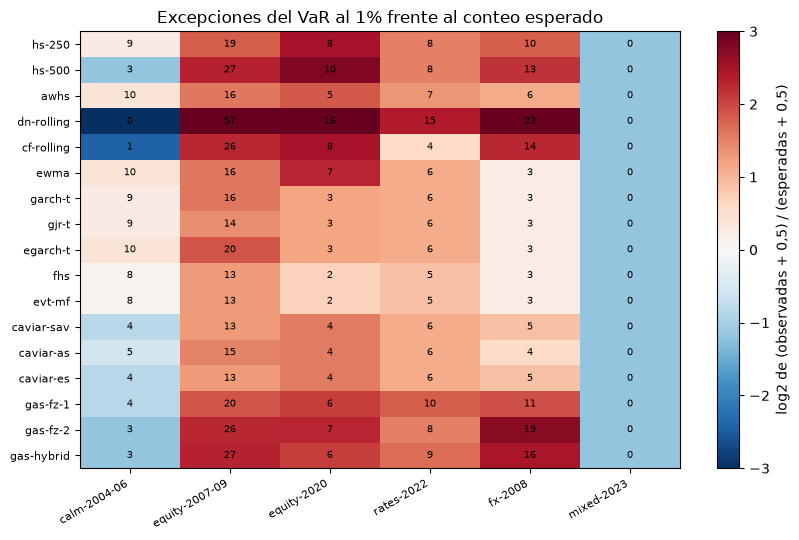

In [11]:
# Dibujar la razón de excepciones observadas a esperadas (escalón por ventana), con los conteos escritos en las celdas
ratio = (counts + 0.5) / (expected + 0.5)               # un desplazamiento de medio conteo mantiene los ceros en la escala logarítmica
fig, ax = plt.subplots(figsize=(8.5, 5.5))
image = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(rungs)))
ax.set_yticklabels(rungs, fontsize=8)
for i in range(len(rungs)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{int(counts[i, j])}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="log2 de (observadas + 0,5) / (esperadas + 0,5)")
ax.set_title("Excepciones del VaR al 1% frente al conteo esperado")
fig.tight_layout()
plt.show()

## Resultados

- **La escalera.** Tiene 18 entradas: 17 escalones ajustados desde la simulación histórica (R1) hasta los modelos GAS-FZ (R9), y `nn-fz` (R10), un retador neuronal que el cálculo registra como no ejecutado. Nada en los datos versionados dice que se haya evaluado un modelo neuronal.
- **Sin mirar hacia adelante.** En las seis ventanas cada muestra de estimación termina antes de su día de pronóstico, y los hiperparámetros se fijaron en 1995-01-01 a 2003-12-31, antes de toda ventana, con `tuned_on_test_window` falso. Son verificaciones sobre el archivo versionado, no promesas de un documento.
- **Ponderación por edad y la cola.** Con $\lambda = 0,99$ y $K = 100$ el número efectivo de días es 92,4 de 100. Al 2,5 por ciento el pronóstico de pesos iguales es 0,020861 para el VaR y 0,021771 para la ES, el ponderado por edad 0,021324 y 0,021933. Al 1 por ciento sobre 100 días la cola es una observación, así que con pesos iguales la ES iguala al VaR (0,022293 ambos): una ES necesita una cola con varias observaciones.
- **EWMA se reproduce.** La ES versionada iguala la ES delta-normal de la volatilidad que implica el VaR versionado con 1e-10, y la recursión iniciada en la primera varianza versionada y alimentada con los retornos realizados reproduce las 251 volatilidades versionadas con una diferencia relativa máxima de 5,9e-9, que es el redondeo del archivo. Con $\lambda = 0,97$ el peso cae bajo 1 por ciento después de 151,2 días. La volatilidad sube de 0,0063 a 0,0146 (día 119) en la crisis, más del doble, lo que una ventana fija de 250 días no puede hacer con rapidez.
- **Normal frente a Cornish-Fisher frente a la muestra.** Los retornos tienen asimetría positiva (0,629) y exceso de curtosis 2,129. Al 1 por ciento el VaR es 0,025085 con la normal, 0,023873 con Cornish-Fisher y 0,023915 empírico; al 2,5 por ciento son 0,021198, 0,018974 y 0,020861. La corrección ayuda al 1 por ciento y se pasa al 2,5 por ciento: es un ajuste de momentos, no un modelo mejor, y la expansión fue válida en ambos casos.
- **Simulación histórica filtrada y EVT sobre residuos EWMA.** Los residuos estandarizados tienen desviación estándar 1,070 y mínimo -3,590. Al 1 por ciento el VaR (ES) del día siguiente es 0,02054 (0,02353) normal, 0,02353 (0,02702) simulación histórica filtrada y 0,02152 (0,02701) EVT. La forma de la GPD depende del umbral: 0,452 con 10 excedencias, 0,235 con 13, 0,045 con 20 y -0,027 con 25, de modo que el índice de cola cambia de signo dentro del rango que un practicante probaría. Con 251 días un umbral de 5 por ciento deja 13 excedencias; el hiperparámetro es un riesgo de modelo, no un detalle.
- **Los ajustes que no se pueden repetir aquí.** GARCH-t registró 105 fallas de convergencia en 504 reajustes en `equity-2007-09`, 100 en 251 en `fx-2008` y 51 en 64 en `mixed-2023`; GAS-FZ de dos factores registró 45 fallas en 92 ajustes en `calm-2004-06` y 14 en 29 en `fx-2008`. CAViaR y GAS-FZ se ajustan en cada nivel de cola, así que sus conteos son el doble del número de fechas de reajuste. Parámetros medianos de GARCH-t en la crisis: $\alpha_1$ 0,0598, $\beta_1$ 0,9189, $\nu$ 8,40.
- **La escalera frente a las ventanas.** Las compuertas sacaron 6, 17, 13, 13, 7 y 0 de los 17 escalones en las seis ventanas. En `equity-2007-09` los 17 superan su VaR al 1 por ciento más de 2,5 veces las 5,0 esperadas (13 a 57 excepciones). En la ventana tranquila las compuertas sacan escalones por la razón opuesta: `dn-rolling` tiene 0 excepciones contra 7,5 esperadas, y los tres escalones GAS-FZ 3 a 4. En `fx-2008` seis escalones (EWMA, los tres GARCH, FHS y EVT) tienen 3 contra 2,5 esperadas, y los tres escalones GAS-FZ 11, 19 y 16.

Lo que este cuaderno no muestra: si un conteo es estadísticamente compatible con su valor esperado (cuaderno 03), los pronósticos de ES (cuaderno 04) ni cuál escalón elegible pronostica mejor (cuaderno 05).

## Resumen

- La escalera es una secuencia de estimadores con fuente, innovación y calendario de reajuste conocidos; el documento versionado registra también el retador que no ejecuta.
- Dos propiedades de un backtest honesto se verifican desde los archivos versionados: cada muestra de estimación termina antes de su día de pronóstico, y los hiperparámetros se fijaron antes de cada ventana.
- Los escalones de forma cerrada se pueden correr y verificar sobre retornos reales con las funciones del motor; un pronóstico EWMA versionado se reproduce con su propia recursión hasta el redondeo, la clase de verificación que debería pasar todo pronóstico versionado.
- GARCH, CAViaR y GAS-FZ necesitan un paquete o un tamaño de muestra que un cuaderno sobre archivos versionados no tiene; su evidencia son los pronósticos versionados y el registro de sus reajustes y fallas de convergencia.
- Ningún escalón gana en todas partes: la cobertura depende de la ventana, y las compuertas sacan muchos escalones en las ventanas de crisis.

**Qué probar después.** Cambia la fracción de umbral en el paso 6 y mira cómo se mueven la forma $\hat\xi$ y el VaR de EVT; luego lee el cuaderno 03 para ver cómo se prueban los conteos de excepciones de arriba.

## Referencias

- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Boudoukh, J., Richardson, M. y Whitelaw, R. (1998), The best of both worlds, Risk 11(5). https://pages.stern.nyu.edu/~rwhitela/papers/hybrid%20risk98.pdf
- J.P. Morgan/Reuters (1996), RiskMetrics Technical Document, 4.ª ed., sección 5.3.2. https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a
- Cornish, E. A. y Fisher, R. A. (1938), Moments and cumulants in the specification of distributions, Revue de l'Institut International de Statistique 5(4). https://doi.org/10.2307/1400905
- Bollerslev, T. (1986), Generalized autoregressive conditional heteroskedasticity, Journal of Econometrics 31(3). https://doi.org/10.1016/0304-4076(86)90063-1
- Glosten, L. R., Jagannathan, R. y Runkle, D. E. (1993), On the relation between the expected value and the volatility of the nominal excess return on stocks, Journal of Finance 48(5). https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Nelson, D. B. (1991), Conditional heteroskedasticity in asset returns: a new approach, Econometrica 59(2). https://doi.org/10.2307/2938260
- McNeil, A. J. y Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Engle, R. F. y Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hull, J. y White, A. (1998), Incorporating volatility updating into the historical simulation method for value-at-risk, Journal of Risk 1(1). https://doi.org/10.21314/JOR.1998.001
- Barone-Adesi, G., Giannopoulos, K. y Vosper, L. (1999), VaR without correlations for portfolios of derivative securities, Journal of Futures Markets 19(5).